## CE2 Phase 3 & 4: Simple and Multiple Linear Regression

### 1. Conceptual Overview & Mathematical Formulations
Linear regression is a foundational supervised parametric technique that models the expected value of a continuous scalar response variable ($y$) as a linear combination of one or more predictor features ($x$).

#### Simple Linear Regression (SLR)
Simple Linear Regression models chronological age as a linear function of a single predictor variable $x$ (the single facial measurement or ratio exhibiting the strongest linear association with age):
$$\text{age} = \beta_0 + \beta_1 x + \epsilon$$
- $\beta_0$ (**Intercept**): The expected value of age when the standardized predictor $x = 0$ (at its training mean).
- $\beta_1$ (**Slope / Regression Coefficient**): The expected change in age associated with a 1-unit increase in $x$ (1 standard deviation increase in standardized space).
- $\epsilon$ (**Residual Error**): The unmodeled stochastic disturbance term, assumed $\epsilon \sim \mathcal{N}(0, \sigma^2)$.

#### Multiple Linear Regression (MLR)
Multiple Linear Regression extends SLR by simultaneously incorporating multiple predictor features ($x_1, x_2, \dots, x_n$), encompassing demographic categories, raw spatial pixel measurements, and engineered scale-invariant ratios:
$$\text{age} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n + \epsilon$$
- $\beta_0$: The baseline expected age when all continuous predictors are at their mean ($z = 0$) and categorical indicators are in their reference baseline states.
- $\beta_j$: The **partial regression coefficient** for predictor $x_j$, reflecting the isolated marginal change in expected age for a 1-unit increase in $x_j$, holding all other predictors strictly constant (*ceteris paribus*).

---

### 2. Evaluation Metrics Definition & Interpretation

To comprehensively evaluate regression model performance, four standard metrics are tracked:

1. **Mean Absolute Error (MAE):**
   $$\text{MAE} = \frac{1}{N} \sum_{i=1}^N |y_i - \hat{y}_i|$$
   - **Interpretation:** The average absolute distance between predicted age and actual age, measured directly in **years**. MAE is linearly proportional to error magnitude and robust to extreme outliers.

2. **Mean Squared Error (MSE):**
   $$\text{MSE} = \frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2$$
   - **Interpretation:** The mean of squared differences between actual and predicted ages (measured in $\text{years}^2$). By squaring deviations, MSE heavily penalizes large errors and outliers.

3. **Root Mean Squared Error (RMSE):**
   $$\text{RMSE} = \sqrt{\text{MSE}} = \sqrt{\frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2}$$
   - **Interpretation:** The square root of MSE, restoring the metric back into the intuitive units of **years**. Because it squares errors prior to averaging, RMSE will always be $\ge \text{MAE}$, with larger gaps indicating high variance in individual prediction errors.

4. **Coefficient of Determination ($R^2$):**
   $$R^2 = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}} = 1 - \frac{\sum_{i=1}^N (y_i - \hat{y}_i)^2}{\sum_{i=1}^N (y_i - \bar{y})^2}$$
   - **Interpretation:** The proportion of variance in chronological age explained by the model's predictor features relative to a naive baseline that always predicts the sample mean ($\bar{y}$).
   - **Benchmarks:**
     - $R^2 = 1.0$: Perfect explanatory power (zero residual variance).
     - $R^2 = 0.0$: Explains no more variance than simply guessing the mean age.
     - $R^2 < 0.0$: Explanatory performance worse than the naive mean prediction (common on unseen test data when an estimator severely misfits).


In [2]:
# Ensure working directory is set to project root
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Suppress harmless runtime warning from NumPy/Accelerate matmul
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

# Core imports for linear modeling, evaluation, and visualization
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load partitioned and scaled datasets from data/processed/
X_train_scaled = pd.read_csv("data/processed/X_train_scaled.csv")
X_test_scaled = pd.read_csv("data/processed/X_test_scaled.csv")

# Convert target datasets to 1D Pandas Series using ["age"]
y_train = pd.read_csv("data/processed/y_train.csv")["age"]
y_test = pd.read_csv("data/processed/y_test.csv")["age"]

# Print dataset dimensions and confirm 1D target structure
print("=== PARTITIONED & SCALED DATASETS LOADED ===")
print(f"X_train_scaled shape : {X_train_scaled.shape}")
print(f"X_test_scaled shape  : {X_test_scaled.shape}")
print(f"y_train shape        : {y_train.shape} (Type: {type(y_train).__name__})")
print(f"y_test shape         : {y_test.shape} (Type: {type(y_test).__name__})")


=== PARTITIONED & SCALED DATASETS LOADED ===
X_train_scaled shape : (2398, 14)
X_test_scaled shape  : (600, 14)
y_train shape        : (2398,) (Type: Series)
y_test shape         : (600,) (Type: Series)


In [4]:
# Define reusable evaluation function across train and test partitions
def evaluate(model, X_tr, y_tr, X_te, y_te, name):
    """
    Computes predictions on training and testing sets, returning a standardized dictionary
    of regression performance metrics: MAE, MSE, RMSE, and R2.
    """
    # Generate predictions
    y_pred_tr = model.predict(X_tr)
    y_pred_te = model.predict(X_te)
    
    # Compute squared errors
    train_mse = mean_squared_error(y_tr, y_pred_tr)
    test_mse = mean_squared_error(y_te, y_pred_te)
    
    return {
        "Model": name,
        "Train_MAE": mean_absolute_error(y_tr, y_pred_tr),
        "Test_MAE": mean_absolute_error(y_te, y_pred_te),
        "Train_MSE": train_mse,
        "Test_MSE": test_mse,
        "Train_RMSE": np.sqrt(train_mse),
        "Test_RMSE": np.sqrt(test_mse),
        "Train_R2": r2_score(y_tr, y_pred_tr),
        "Test_R2": r2_score(y_te, y_pred_te)
    }

print("Reusable evaluate() function defined successfully.")


Reusable evaluate() function defined successfully.


In [5]:
from IPython.display import display, Markdown

# Fit DummyRegressor baseline that always predicts the training mean age
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train_scaled, y_train)

# Evaluate baseline model on training and testing sets
baseline_results = evaluate(
    dummy_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
    "Baseline (Mean)"
)

print("=== BASELINE REGRESSOR PERFORMANCE METRICS ===")
for metric, val in baseline_results.items():
    if metric != "Model":
        print(f"  {metric:<12}: {val:.4f}")
    else:
        print(f"  {metric:<12}: {val}")

# Markdown note explaining baseline benchmark role
display(Markdown(
    f"> **Baseline Benchmark Note:** The `DummyRegressor(strategy='mean')` baseline always predicts "
    f"the training set mean age ($\mu = {y_train.mean():.2f}$ years) for every observation. "
    f"It achieves a training $R^2 = 0.0000$ by definition. Any statistically useful predictive regression "
    f"model must outperform this baseline by demonstrating lower errors (MAE, RMSE) and a positive test $R^2$."
))


=== BASELINE REGRESSOR PERFORMANCE METRICS ===
  Model       : Baseline (Mean)
  Train_MAE   : 15.5015
  Test_MAE    : 16.5798
  Train_MSE   : 402.3679
  Test_MSE    : 445.1925
  Train_RMSE  : 20.0591
  Test_RMSE   : 21.0996
  Train_R2    : 0.0000
  Test_R2     : -0.0021


> **Baseline Benchmark Note:** The `DummyRegressor(strategy='mean')` baseline always predicts the training set mean age ($\mu = 33.22$ years) for every observation. It achieves a training $R^2 = 0.0000$ by definition. Any statistically useful predictive regression model must outperform this baseline by demonstrating lower errors (MAE, RMSE) and a positive test $R^2$.

In [6]:
# Define the 7 continuous numerical features
continuous_cols = [
    'eye_distance', 'mouth_width', 'face_width', 'face_height',
    'face_aspect_ratio', 'eye_to_face_ratio', 'mouth_to_face_ratio'
]

# Compute Pearson correlation with target age using TRAINING data only
train_correlations = X_train_scaled[continuous_cols].apply(lambda col: col.corr(y_train))
sorted_correlations = train_correlations.reindex(
    train_correlations.abs().sort_values(ascending=False).index
)

print("=== TRAINING DATA CORRELATIONS WITH AGE (SORTED BY |r|) ===")
for feat, r_val in sorted_correlations.items():
    print(f"  {feat:<22}: r = {r_val:+.4f} (|r| = {abs(r_val):.4f})")

# Dynamically select the single feature with highest absolute correlation (no hardcoding)
best_feature = sorted_correlations.abs().idxmax()
print(f"\nSelected Best Predictor for Simple Linear Regression: '{best_feature}' (r = {train_correlations[best_feature]:+.4f})")

# Fit Simple Linear Regression model on training data
simple_lr = LinearRegression()
simple_lr.fit(X_train_scaled[[best_feature]], y_train)

# Extract fitted intercept and slope parameters
intercept_simple = simple_lr.intercept_
slope_simple = simple_lr.coef_[0]

print("\n=== SIMPLE LINEAR REGRESSION MODEL PARAMETERS ===")
print(f"  Intercept (beta_0) : {intercept_simple:.4f}")
print(f"  Slope (beta_1)     : {slope_simple:.4f}")
print(f"  Fitted Equation    : Predicted Age = {intercept_simple:.2f} + ({slope_simple:.2f} * {best_feature})")

# Evaluate Simple Linear Regression on train and test sets
simple_results = evaluate(
    simple_lr,
    X_train_scaled[[best_feature]],
    y_train,
    X_test_scaled[[best_feature]],
    y_test,
    f"Simple LR ({best_feature})"
)

print("\n=== SIMPLE LINEAR REGRESSION PERFORMANCE METRICS ===")
for metric, val in simple_results.items():
    if metric != "Model":
        print(f"  {metric:<12}: {val:.4f}")
    else:
        print(f"  {metric:<12}: {val}")


=== TRAINING DATA CORRELATIONS WITH AGE (SORTED BY |r|) ===
  face_aspect_ratio     : r = +0.2585 (|r| = 0.2585)
  mouth_to_face_ratio   : r = +0.2425 (|r| = 0.2425)
  eye_to_face_ratio     : r = +0.2252 (|r| = 0.2252)
  face_width            : r = -0.2086 (|r| = 0.2086)
  face_height           : r = +0.1386 (|r| = 0.1386)
  mouth_width           : r = +0.1036 (|r| = 0.1036)
  eye_distance          : r = -0.0203 (|r| = 0.0203)

Selected Best Predictor for Simple Linear Regression: 'face_aspect_ratio' (r = +0.2585)

=== SIMPLE LINEAR REGRESSION MODEL PARAMETERS ===
  Intercept (beta_0) : 33.2235
  Slope (beta_1)     : 5.1852
  Fitted Equation    : Predicted Age = 33.22 + (5.19 * face_aspect_ratio)

=== SIMPLE LINEAR REGRESSION PERFORMANCE METRICS ===
  Model       : Simple LR (face_aspect_ratio)
  Train_MAE   : 15.2493
  Test_MAE    : 16.1086
  Train_MSE   : 375.4821
  Test_MSE    : 413.6566
  Train_RMSE  : 19.3774
  Test_RMSE   : 20.3385
  Train_R2    : 0.0668
  Test_R2     : 0.0689


/Users/cipherxishant/Desktop/AIML-Project/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


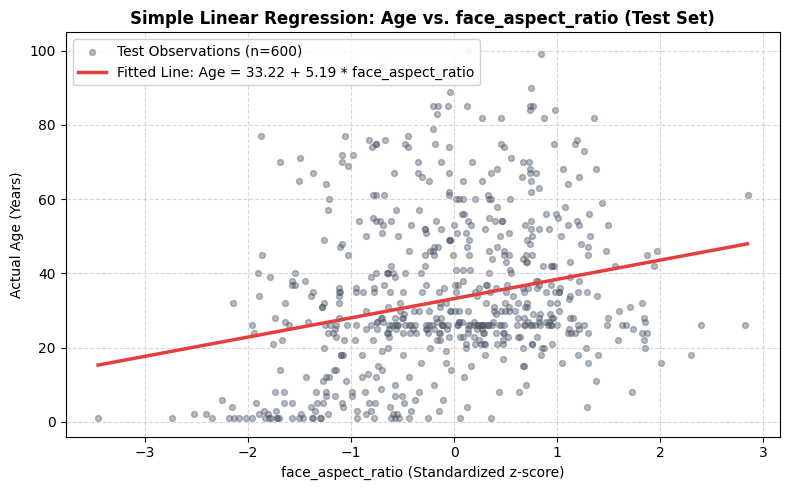

In [7]:
# Ensure visualization directory exists
os.makedirs("visualizations", exist_ok=True)

# Generate points along the fitted regression line over test feature range
x_line = np.linspace(
    X_test_scaled[best_feature].min(),
    X_test_scaled[best_feature].max(),
    200
).reshape(-1, 1)
y_line = simple_lr.predict(x_line)

# Create scatter plot of test observations and fitted regression line
plt.figure(figsize=(8, 5))
plt.scatter(
    X_test_scaled[best_feature],
    y_test,
    color="#4a5568",
    alpha=0.4,
    s=18,
    label="Test Observations (n=600)"
)
plt.plot(
    x_line,
    y_line,
    color="#e53e3e",
    linewidth=2.5,
    label=f"Fitted Line: Age = {intercept_simple:.2f} + {slope_simple:.2f} * {best_feature}"
)

# Labeling and styling
plt.title(f"Simple Linear Regression: Age vs. {best_feature} (Test Set)", fontsize=12, fontweight="bold")
plt.xlabel(f"{best_feature} (Standardized z-score)", fontsize=10)
plt.ylabel("Actual Age (Years)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()

# Save visualization figure to file and display inline
plt.savefig("visualizations/06_simple_regression_fit.png", dpi=150)
plt.show()


In [8]:
# THE DUMMY VARIABLE TRAP:
# When categorical features are one-hot encoded, the sum of dummy columns equals 1
# (e.g., gender_0 + gender_1 = 1; sum(race_0 to race_4) = 1).
# Including all dummy levels alongside an intercept term creates perfect multicollinearity (singular matrix X^T X),
# rendering Ordinary Least Squares (OLS) normal equation coefficients mathematically non-invertible or unstable.
# To avoid the dummy variable trap, we drop one reference baseline dummy column per categorical variable:
# dropping 'gender_0' (Male reference group) and 'race_0' (White reference group).

X_train_mlr = X_train_scaled.drop(columns=["gender_0", "race_0"])
X_test_mlr = X_test_scaled.drop(columns=["gender_0", "race_0"])

# Fit Multiple Linear Regression model on training features
mlr_model = LinearRegression()
mlr_model.fit(X_train_mlr, y_train)

# Evaluate Multiple Linear Regression on train and test sets
mlr_results = evaluate(
    mlr_model,
    X_train_mlr,
    y_train,
    X_test_mlr,
    y_test,
    "Multiple Linear Regression"
)

print("=== MULTIPLE LINEAR REGRESSION PERFORMANCE METRICS ===")
for metric, val in mlr_results.items():
    if metric != "Model":
        print(f"  {metric:<12}: {val:.4f}")
    else:
        print(f"  {metric:<12}: {val}")

# Construct DataFrame of feature coefficients sorted by absolute magnitude
coef_df = pd.DataFrame({
    "Feature": X_train_mlr.columns,
    "Coefficient": mlr_model.coef_
})
coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values(by="Abs_Coefficient", ascending=False).drop(columns=["Abs_Coefficient"])

print(f"\nModel Intercept (beta_0): {mlr_model.intercept_:.4f}")
print("  (Expected age for baseline group: Male, Race_0 with mean continuous measurements)")
print("\nModel Coefficients (sorted by absolute magnitude):")
print(coef_df.to_string(index=False))


=== MULTIPLE LINEAR REGRESSION PERFORMANCE METRICS ===
  Model       : Multiple Linear Regression
  Train_MAE   : 13.8583
  Test_MAE    : 14.7200
  Train_MSE   : 331.2289
  Test_MSE    : 367.9220
  Train_RMSE  : 18.1997
  Test_RMSE   : 19.1813
  Train_R2    : 0.1768
  Test_R2     : 0.1719

Model Intercept (beta_0): 39.0199
  (Expected age for baseline group: Male, Race_0 with mean continuous measurements)

Model Coefficients (sorted by absolute magnitude):
            Feature  Coefficient
       eye_distance   -45.356745
        mouth_width    38.221386
mouth_to_face_ratio   -33.066391
  eye_to_face_ratio    32.018143
  face_aspect_ratio   -29.635746
        face_height    18.348785
         face_width   -15.778677
             race_4   -14.194290
             race_2    -9.911493
             race_1    -5.311558
             race_3    -5.183986
           gender_1    -3.122742


In [7]:
# Generate predictions on test set for both models
y_pred_simple = simple_lr.predict(X_test_scaled[[best_feature]])
y_pred_mlr = mlr_model.predict(X_test_mlr)

# Create side-by-side diagnostic plots of Actual vs. Predicted values
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

min_val = min(y_test.min(), y_pred_simple.min(), y_pred_mlr.min())
max_val = max(y_test.max(), y_pred_simple.max(), y_pred_mlr.max())

# Subplot 1: Simple Linear Regression
axes[0].scatter(y_pred_simple, y_test, color="#3182ce", alpha=0.4, s=18, label="Test Observations")
axes[0].plot([min_val, max_val], [min_val, max_val], color="#e53e3e", linestyle="--", linewidth=2, label="Ideal (y = x)")
axes[0].set_title(
    f"Simple LR ({best_feature})\nTest R² = {simple_results['Test_R2']:.4f}, RMSE = {simple_results['Test_RMSE']:.2f} yrs",
    fontsize=11, fontweight="bold"
)
axes[0].set_xlabel("Predicted Age (Years)", fontsize=10)
axes[0].set_ylabel("Actual Age (Years)", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(frameon=True, facecolor="white")

# Subplot 2: Multiple Linear Regression
axes[1].scatter(y_pred_mlr, y_test, color="#2b6cb0", alpha=0.4, s=18, label="Test Observations")
axes[1].plot([min_val, max_val], [min_val, max_val], color="#e53e3e", linestyle="--", linewidth=2, label="Ideal (y = x)")
axes[1].set_title(
    f"Multiple Linear Regression\nTest R² = {mlr_results['Test_R2']:.4f}, RMSE = {mlr_results['Test_RMSE']:.2f} yrs",
    fontsize=11, fontweight="bold"
)
axes[1].set_xlabel("Predicted Age (Years)", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(frameon=True, facecolor="white")

plt.suptitle("Actual vs. Predicted Age on Test Set (Linear Models)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()

# Save diagnostic plot to visualizations/
plt.savefig("visualizations/07_actual_vs_predicted_linear.png", dpi=150, bbox_inches="tight")
plt.show()


In [8]:
# Compile model evaluation results into comparison DataFrame
results_df = pd.DataFrame([baseline_results, simple_results, mlr_results])

# Reorder columns logically
columns_order = [
    "Model", "Train_MAE", "Test_MAE", "Train_RMSE", "Test_RMSE",
    "Train_R2", "Test_R2", "Train_MSE", "Test_MSE"
]
results_df = results_df[columns_order]

print("=== CE2 LINEAR REGRESSION MODELS PERFORMANCE SUMMARY ===")
print(results_df.round(4).to_string(index=False))

# Save performance metrics to CSV
results_csv_path = "data/processed/ce2_model_results.csv"
results_df.to_csv(results_csv_path, index=False)
print(f"\nModel comparison results saved successfully to '{results_csv_path}'.")


=== CE2 LINEAR REGRESSION MODELS PERFORMANCE SUMMARY ===
                        Model  Train_MAE  Test_MAE  Train_RMSE  Test_RMSE  Train_R2  Test_R2  Train_MSE  Test_MSE
              Baseline (Mean)    15.5015   16.5798     20.0591    21.0996    0.0000  -0.0021   402.3679  445.1925
Simple LR (face_aspect_ratio)    15.2493   16.1086     19.3774    20.3385    0.0668   0.0689   375.4821  413.6566
   Multiple Linear Regression    13.8583   14.7200     18.1997    19.1813    0.1768   0.1719   331.2289  367.9220

Model comparison results saved successfully to 'data/processed/ce2_model_results.csv'.


### Observation

*Placeholder for user observations on empirical model performance, comparison across Baseline, Simple LR, and Multiple LR, coefficient magnitudes, and actual vs. predicted distributions:*
- [Compare baseline dummy model error against Simple Linear Regression error.]
- [Discuss the improvement gained when expanding from single-feature Simple LR to 12-feature Multiple Linear Regression.]
- [Analyze the magnitude and signs of key coefficients (e.g. face_aspect_ratio, eye_distance, demographic indicators).]
- [Examine the Actual vs. Predicted scatter plots and evaluate deviations from the ideal y = x line.]
